# 05 – Classification model: high utilization in 30 minutes
**Parking Analytics Zurich · Person C**

**Question:** *Will a garage be highly utilized (occupancy ≥ 85 %) in 30 minutes?*
This is a binary classification problem with labelled data, so it is solved with supervised learning (Week 08/09).

| Step | Choice | Why |
|---|---|---|
| Target | `high_in_30 = occupancy(t + 30 min) ≥ 0.85` | threshold chosen in 03_eda |
| Features | current occupancy, change over the last 15 and 30 min, hour, weekday, weekend, garage, capacity, precipitation, temperature | what a driver's app would know at time t |
| Baseline | persistence: "high in 30 min if high now" | the model must beat this simple rule |
| Models | logistic regression vs. random forest | linear and interpretable vs. non-linear ensemble (Week 09) |
| Decision threshold | chosen on a validation period (last 2 training days) to maximise F1 | the default 0.5 is not necessarily best for a rare class; the test set is never used for this choice |
| Split | by time: last days = test set, never random | random splits leak neighbouring 15-min slots into the test set |
| Metrics | precision, recall, F1, confusion matrix | accuracy is misleading when only a small share of cases is positive |

**Project requirements covered here:**
- **5 – Modelling beyond a standard prediction:** classification, plus a comparison of model quality between groups (weekday vs. weekend, garage clusters from B's k-means).
- **6 – Evaluation:** precision, recall, F1, confusion matrix, compared with a baseline.
- **7 – Interpretation:** feature importance, coefficients, where the model fails.
- **Bonus 1 – Creativity:** 30-minute-ahead forecast and a separate evaluation of the hard cases (garages that are *about to* become full).

**Data:** B's cleaned data (`occupancy_clean`) with real capacities, joined with A's hourly weather, loaded with `load_data()` from PostgreSQL (or the CSV files if no database connection is configured). Re-run after the final cut-off date; nothing needs to change.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

from src.analysis_prep import load_data, caption

FIG_DIR = Path.cwd().parent / "figures" / "analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

THRESHOLD = 0.85
HORIZON = pd.Timedelta("30min")
TEST_DAYS = 7          # last week = test set
RANDOM_STATE = 42

## 1. Build the dataset

In [2]:
df = load_data()

s = df[["parking_id", "slot_utc", "occupancy_rate"]]

def shifted(delta, name):
    # value of the same garage at slot_utc + delta, looked up by TIME (not by row position)
    return s.assign(slot_utc=s.slot_utc - delta).rename(columns={"occupancy_rate": name})

data = (df.merge(shifted(HORIZON, "occ_future"), on=["parking_id", "slot_utc"], how="left")
          .merge(shifted(-pd.Timedelta("15min"), "occ_lag15"), on=["parking_id", "slot_utc"], how="left")
          .merge(shifted(-pd.Timedelta("30min"), "occ_lag30"), on=["parking_id", "slot_utc"], how="left"))

data["delta_15"] = data.occupancy_rate - data.occ_lag15
data["delta_30"] = data.occupancy_rate - data.occ_lag30
data["high_now"] = (data.occupancy_rate >= THRESHOLD).astype(int)
data["high_in_30"] = (data.occ_future >= THRESHOLD).astype(int)
# hour as a cycle, so that 23:00 and 00:00 are close to each other
data["hour_sin"] = np.sin(2 * np.pi * data.minute_of_day / 1440)
data["hour_cos"] = np.cos(2 * np.pi * data.minute_of_day / 1440)

before = len(data)
data = data.dropna(subset=["occ_future", "delta_15", "delta_30"])
print(f"Rows with target and lag features: {len(data):,} of {before:,} ({len(data)/before:.0%})")
# Weather is fetched once a day, so the most recent hours have none yet: leave them out
n = len(data)
data = data.dropna(subset=["temperature_c", "precipitation_mm"]).reset_index(drop=True)
print(f"Rows without weather left out: {n - len(data):,}")
print(f"Positive class (high in 30 min): {data.high_in_30.mean():.1%}")

PostgreSQL not reachable (OperationalError: connection is bad: connection to server on socket "/tmp/.s.PGSQL.5433" failed: No such file or directory
	Is the server running locally and accepting connections on that socket?) – falling back to the CSV files.
Data source: CSV files (data/processed, data/raw)
57,742 rows · 33 garages · 20.10.2026 – 09.11.2026 · weather missing for 4.8% of rows


Rows with target and lag features: 56,240 of 57,742 (97%)
Rows without weather left out: 2,541
Positive class (high in 30 min): 10.8%


## 2. Time-based train/test split

In [3]:
# Split on local calendar days: the last TEST_DAYS days are the test set
cutoff = data.slot_local.max().normalize() - pd.Timedelta(days=TEST_DAYS - 1)
train, test = data[data.slot_local < cutoff], data[data.slot_local >= cutoff]
print(f"Train: {train.slot_local.min():%d.%m} – {train.slot_local.max():%d.%m}  ({len(train):,} rows, {train.high_in_30.mean():.1%} positive)")
print(f"Test:  {test.slot_local.min():%d.%m} – {test.slot_local.max():%d.%m}  ({len(test):,} rows, {test.high_in_30.mean():.1%} positive)")
CAPTION = (f"Source: own 15-min collection of the PLS feed (City of Zurich), cleaned; weather: Open-Meteo · train {train.slot_local.min():%d.%m.}–{train.slot_local.max():%d.%m.}, "
           f"test {test.slot_local.min():%d.%m.}–{test.slot_local.max():%d.%m.%Y} · n(test) = {len(test):,}")

Train: 22.10 – 02.11  (35,432 rows, 10.6% positive)
Test:  03.11 – 09.11  (18,267 rows, 11.3% positive)


## 3. Models

In [4]:
WEATHER = ["precipitation_mm", "temperature_c"]
NUM = ["occupancy_rate", "delta_15", "delta_30", "hour_sin", "hour_cos", "capacity_used", "is_weekend"] + WEATHER
CAT = ["parking_id", "weekday"]
FEATURES = NUM + CAT
X_train, y_train = train[FEATURES], train.high_in_30
X_test, y_test = test[FEATURES], test.high_in_30

VAL_DAYS = 2
val_cut = train.slot_local.max().normalize() - pd.Timedelta(days=VAL_DAYS - 1)
fit_part, val_part = train[train.slot_local < val_cut], train[train.slot_local >= val_cut]

def make_model(kind, num_cols):
    pre = ColumnTransformer([("num", StandardScaler(), num_cols),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    clf = (LogisticRegression(max_iter=2000) if kind == "lr" else
           RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE))
    return Pipeline([("pre", pre), ("clf", clf)])

def fit_with_threshold(kind, num_cols):
    # 1) fit on the earlier training days, 2) pick the threshold with the best F1 on the validation days,
    # 3) refit on the full training period. The test set is not touched.
    cols = num_cols + CAT
    m = make_model(kind, num_cols).fit(fit_part[cols], fit_part.high_in_30)
    prob_val = m.predict_proba(val_part[cols])[:, 1]
    grid = np.arange(0.15, 0.80, 0.05)
    best = max(grid, key=lambda t: f1_score(val_part.high_in_30, prob_val >= t))
    m = make_model(kind, num_cols).fit(train[cols], train.high_in_30)
    return m, float(best)

models, thresholds = {}, {}
for name, kind in [("Logistic regression", "lr"), ("Random forest", "rf")]:
    models[name], thresholds[name] = fit_with_threshold(kind, NUM)
print(f"Validation period: {val_part.slot_local.min():%d.%m} – {val_part.slot_local.max():%d.%m}")
print("Chosen decision thresholds:", {k: round(v, 2) for k, v in thresholds.items()})

pred = {"Baseline (persistence)": test.high_now.values}
for name, m in models.items():
    pred[name] = (m.predict_proba(X_test)[:, 1] >= thresholds[name]).astype(int)

Validation period: 01.11 – 02.11
Chosen decision thresholds: {'Logistic regression': 0.6, 'Random forest': 0.5}


## 4. Evaluation

In [5]:
def scores(y, p):
    return {"precision": precision_score(y, p, zero_division=0),
            "recall": recall_score(y, p, zero_division=0),
            "F1": f1_score(y, p, zero_division=0)}

results = pd.DataFrame({name: scores(y_test, p) for name, p in pred.items()}).T
results.round(3)

,precision,recall,F1
Baseline (persistence),0.882,0.883,0.883
Logistic regression,0.914,0.894,0.904
Random forest,0.908,0.889,0.899


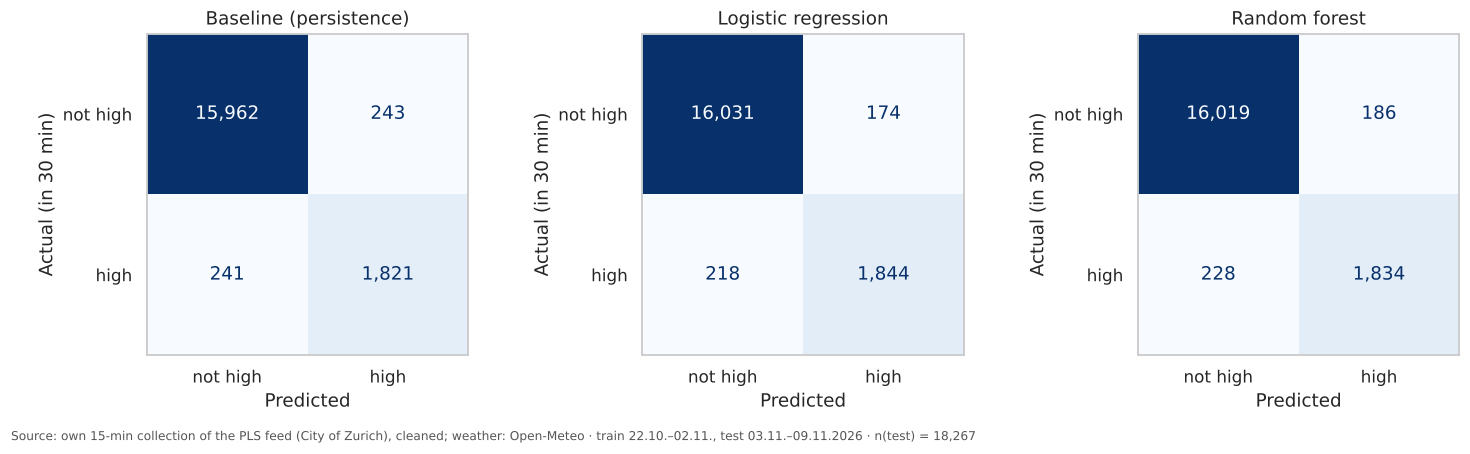

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, p) in zip(axes, pred.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["not high", "high"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set(title=name, xlabel="Predicted", ylabel="Actual (in 30 min)")
    ax.grid(False)
fig.tight_layout()
fig.tight_layout(); fig.text(0.01, 0, CAPTION, ha="left", va="top", fontsize=8, color="#555555")
fig.savefig(FIG_DIR / "model_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.1 The hard cases: transitions
Most positives are garages that are *already* full and stay full. The useful question for a driver is: **will a garage that is not full now become full in the next 30 minutes?** We therefore evaluate separately on the rows where the garage is currently below 85 %.

In [7]:
mask = test.high_now.values == 0
y_tr = y_test.values[mask]
print(f"Test rows not high now: {mask.sum():,}, of which become high in 30 min: {y_tr.sum()}")
transitions = pd.DataFrame({name: scores(y_tr, p[mask]) for name, p in pred.items()}).T
transitions.round(3)

Test rows not high now: 16,203, of which become high in 30 min: 241


,precision,recall,F1
Baseline (persistence),0.000,0.000,0.000
Logistic regression,0.672,0.357,0.466
Random forest,0.861,0.129,0.224


### 4.2 Comparison beyond prediction: weekday vs. weekend

In [8]:
rows = []
for day_type, m in [("Weekday", test.is_weekend.values == 0), ("Weekend", test.is_weekend.values == 1)]:
    for name, p in pred.items():
        rows.append({"day_type": day_type, "model": name, "n": int(m.sum()), **scores(y_test.values[m], p[m])})
by_day = pd.DataFrame(rows).set_index(["day_type", "model"])
by_day.round(3)

n  precision  recall     F1
day_type model                                                  
Weekday  Baseline (persistence)  12195      0.866   0.867  0.866
         Logistic regression     12195      0.900   0.885  0.892
         Random forest           12195      0.894   0.876  0.885
Weekend  Baseline (persistence)   6072      0.911   0.912  0.912
         Logistic regression      6072      0.938   0.911  0.924
         Random forest            6072      0.932   0.912  0.922

### 4.3 Does the weather help the prediction? (RQ3)
Same random forest (same procedure, own validated threshold), trained once without the two weather features. If F1 hardly changes, the weather adds little on top of the current occupancy.

In [9]:
NUM_NW = [c for c in NUM if c not in WEATHER]
rf_nw, t_nw = fit_with_threshold("rf", NUM_NW)
p_nw = (rf_nw.predict_proba(test[NUM_NW + CAT])[:, 1] >= t_nw).astype(int)
weather_check = pd.DataFrame({
    "Random forest with weather": {**scores(y_test, pred["Random forest"]), "F1 transitions": scores(y_tr, pred["Random forest"][mask])["F1"]},
    "Random forest without weather": {**scores(y_test, p_nw), "F1 transitions": scores(y_tr, p_nw[mask])["F1"]},
}).T
weather_check.round(3)

,precision,recall,F1,F1 transitions
Random forest with weather,0.908,0.889,0.899,0.224
Random forest without weather,0.918,0.881,0.899,0.159


### 4.4 Comparison by garage cluster (after B delivers k-means)

In [10]:
clusters_file = Path.cwd().parent / "data" / "processed" / "garage_clusters.csv"
if clusters_file.exists():
    cl = pd.read_csv(clusters_file).set_index("parking_id")["cluster"]
    tc = test.parking_id.map(cl).values
    rows = [{"cluster": c, "model": name, "n": int((tc == c).sum()), **scores(y_test.values[tc == c], p[tc == c])}
            for c in sorted(pd.unique(tc[~pd.isna(tc)])) for name, p in pred.items()]
    display(pd.DataFrame(rows).set_index(["cluster", "model"]).round(3))
else:
    print("Cluster file not available yet (B: data/processed/garage_clusters.csv with parking_id, cluster).")

Cluster file not available yet (B: data/processed/garage_clusters.csv with parking_id, cluster).


## 5. Interpretation: which features matter?

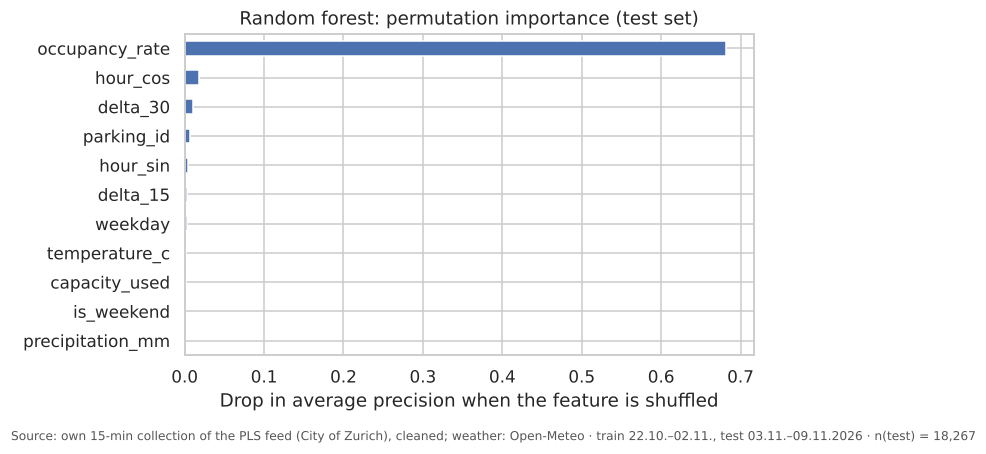

occupancy_rate      0.6822
hour_cos            0.0182
delta_30            0.0104
parking_id          0.0071
hour_sin            0.0048
delta_15            0.0030
weekday             0.0024
temperature_c       0.0022
capacity_used       0.0013
is_weekend          0.0009
precipitation_mm    0.0001
dtype: float64

In [11]:
rf = models["Random forest"]
imp = permutation_importance(rf, X_test, y_test, scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
importance.plot.barh(ax=ax, color="#4C72B0")
ax.set(xlabel="Drop in average precision when the feature is shuffled", title="Random forest: permutation importance (test set)")
fig.tight_layout(); fig.text(0.01, 0, CAPTION, ha="left", va="top", fontsize=8, color="#555555")
fig.savefig(FIG_DIR / "model_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).round(4)

In [12]:
lr = models["Logistic regression"]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
print("Logistic regression – numeric coefficients (standardised features, log-odds):")
coef[[c for c in coef.index if c.startswith("num__")]].sort_values().round(2)

Logistic regression – numeric coefficients (standardised features, log-odds):


num__hour_cos           -0.38
num__capacity_used      -0.13
num__temperature_c      -0.07
num__precipitation_mm   -0.03
num__is_weekend         -0.01
num__delta_15            0.07
num__hour_sin            0.17
num__delta_30            0.71
num__occupancy_rate      8.26
dtype: float64

### 5.1 Where does the model fail?

In [13]:
err = test.assign(pred=pred["Random forest"])
per_garage = (err.groupby("parking_name")
                 .apply(lambda g: pd.Series({"positives": g.high_in_30.sum(),
                                             "missed (FN)": ((g.pred == 0) & (g.high_in_30 == 1)).sum(),
                                             "false alarms (FP)": ((g.pred == 1) & (g.high_in_30 == 0)).sum()}),
                        include_groups=False)
                 .sort_values("positives", ascending=False))
per_garage.head(12)

,positives,missed (FN),false alarms (FP)
parking_name,,,
Talgarten,219,20,18
Globus,154,9,9
USZ Süd,142,10,6
Utoquai,137,11,7
Urania,134,16,13
Theater 11,126,15,16
Jelmoli,121,9,10
Parkside,120,11,5
Opéra,117,14,15


## 6. Interpretation (draft)

In [14]:
r = results.round(3); t = transitions.round(3)
print("All test rows:"); print(r.to_string())
print("\nTransitions only:"); print(t.to_string())
print("\nTop 3 features:", ", ".join(importance.sort_values(ascending=False).index[:3]))

All test rows:
                        precision  recall     F1
Baseline (persistence)      0.882   0.883  0.883
Logistic regression         0.914   0.894  0.904
Random forest               0.908   0.889  0.899

Transitions only:
                        precision  recall     F1
Baseline (persistence)      0.000   0.000  0.000
Logistic regression         0.672   0.357  0.466
Random forest               0.861   0.129  0.224

Top 3 features: occupancy_rate, hour_cos, delta_30


*Status: trained on 22 Oct – 2 Nov (threshold chosen on 1–2 Nov), tested on 3–9 Nov 2026, B's cleaned data with real capacities and A's weather. Re-check the numbers after the final run.*

- **Both models beat the baseline.** On all test rows, F1 rises from 0.883 (persistence) to 0.904 (logistic regression) and 0.899 (random forest). Precision improves most (0.91 vs. 0.88): the models raise fewer false alarms than simply copying the current state.
- **The hard cases are garages that are about to fill up.** Of the 241 test cases in which a garage below 85 % became full within 30 minutes, the baseline catches none. The logistic regression catches 36 % of them, and two out of three of its alarms are correct (precision 0.67). The random forest is more cautious: it catches only 13 %, but 86 % of its alarms are correct. For a driver app, the logistic regression is the more useful model here; a lower decision threshold would catch more of these cases at the cost of more false alarms.
- **What drives the prediction:** the current occupancy dominates by far. Then follow the time of day and the change over the last 30 minutes (a garage that is filling up quickly), then the garage itself. Weekday, capacity, temperature and precipitation add very little once the current occupancy is known.
- **RQ3 in the model:** without the two weather features the random forest reaches the same overall F1 (0.899) and a slightly lower F1 on the transitions (0.16 vs. 0.22). Weather is therefore not a strong predictor, which matches the EDA.
- **Comparison between groups (weekday vs. weekend):** the models are better than the baseline on both day types (F1 0.89 vs. 0.87 on weekdays, 0.92 vs. 0.91 at weekends). Weekends are easier to predict, probably because occupancy changes more slowly there. The comparison by B's k-means clusters follows once `garage_clusters.csv` exists.
- **Where it fails:** missed cases and false alarms are concentrated at the busiest central garages that often hover around the threshold (Talgarten, Urania, Theater 11, Opéra).
- **Limitations:** about three weeks of data and one test week; the 30-minute target relies on regular 15-minute snapshots, and collector gaps reduce the usable pairs.
